# 03 · Windows, features and targets (pipeline step 4)

**What this step does:** cut every segment into windows of 20 frames (1.0 s). For every window we compute

- **22 features per frame:** positions relative to the head, velocities, hand speeds, head height and grip,
- **36 targets:** how far the head and both hands move after 0.25, 0.5, 0.75 and 1.0 s (4 horizons x 3 points x 3 axes).

The full list is in the docstring of `strikefit_ml/feature_engineering.py`. A window never goes outside its segment.

**Input:** `data/interim/`. **Output:** the figures `features_*.png` (the windows themselves are rebuilt when needed).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from strikefit_ml.feature_engineering import FEATURE_NAMES, N_FEATURES, segment_windows, target_names
from strikefit_ml.ingestion import load_config, resolve
from strikefit_ml.preprocessing import load_segments

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
cfg = load_config()
figures = resolve(cfg, "figures_dir")
figures.mkdir(parents=True, exist_ok=True)
segments = load_segments(resolve(cfg, "interim_dir"))
horizons, rate = cfg["horizons_frames"], cfg["sample_rate_hz"]
print(len(FEATURE_NAMES), "features per frame:", FEATURE_NAMES)
print(len(target_names(horizons)), "targets, the first ones:", target_names(horizons)[:6], "...")

22 features per frame: ['head_rel_x', 'head_rel_y', 'head_rel_z', 'controlling_hand_rel_x', 'controlling_hand_rel_y', 'controlling_hand_rel_z', 'secondary_hand_rel_x', 'secondary_hand_rel_y', 'secondary_hand_rel_z', 'head_vel_x', 'head_vel_y', 'head_vel_z', 'controlling_hand_vel_x', 'controlling_hand_vel_y', 'controlling_hand_vel_z', 'secondary_hand_vel_x', 'secondary_hand_vel_y', 'secondary_hand_vel_z', 'controlling_hand_speed', 'secondary_hand_speed', 'head_height_z', 'grip']
36 targets, the first ones: ['h5_head_dx', 'h5_head_dy', 'h5_head_dz', 'h5_controlling_hand_dx', 'h5_controlling_hand_dy', 'h5_controlling_hand_dz'] ...


## Windows of one segment

In [2]:
windows = segment_windows(segments[0], cfg)
print({name: array.shape for name, array in windows.items()})
assert windows["x"].shape[1:] == (cfg["window_frames"], N_FEATURES)
assert windows["y"].shape[1] == 9 * len(horizons)
print(f"'now' frames t0: {windows['t0'][:5]} ... {windows['t0'][-1]} of {segments[0].frames} frames "
      f"(the last {max(horizons)} frames are only used as targets)")

{'x': (833, 20, 22), 'y': (833, 36), 't0': (833,), 'raw': (833, 20, 10)}
'now' frames t0: [19 21 23 25 27] ... 1683 of 1705 frames (the last 20 frames are only used as targets)


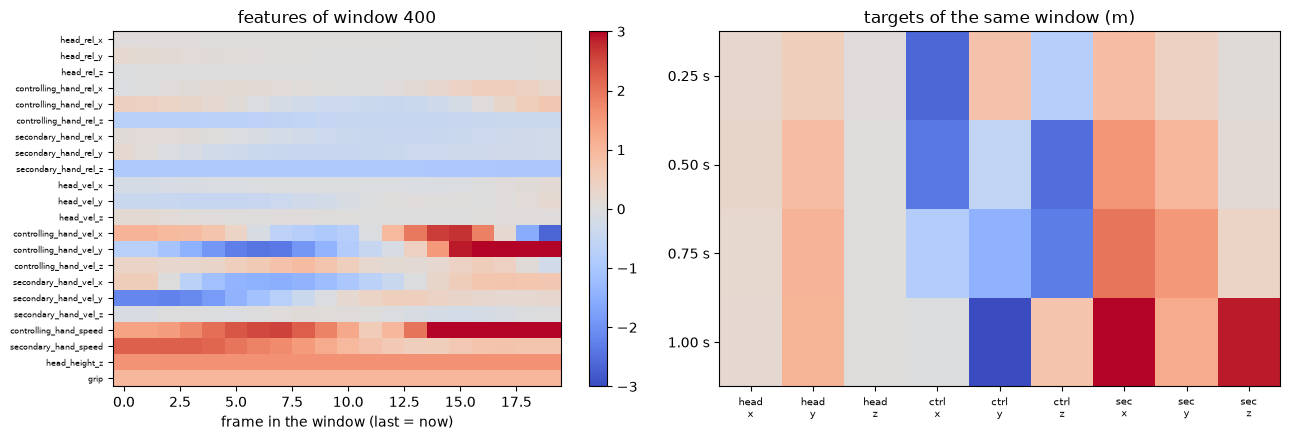

In [3]:
i = 400  # which window to show
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
image = ax[0].imshow(windows["x"][i].T, aspect="auto", cmap="coolwarm", vmin=-3, vmax=3)
ax[0].set_yticks(range(N_FEATURES))
ax[0].set_yticklabels(FEATURE_NAMES, fontsize=6)
ax[0].set_xlabel("frame in the window (last = now)")
ax[0].set_title(f"features of window {i}")
fig.colorbar(image, ax=ax[0])
ax[1].imshow(windows["y"][i].reshape(len(horizons), 9), cmap="coolwarm", aspect="auto")
ax[1].set_xticks(range(9))
ax[1].set_xticklabels([f"{point}\n{axis}" for point in ("head", "ctrl", "sec") for axis in "xyz"], fontsize=7)
ax[1].set_yticks(range(len(horizons)))
ax[1].set_yticklabels([f"{h / rate:.2f} s" for h in horizons])
ax[1].set_title("targets of the same window (m)")
fig.tight_layout()
fig.savefig(figures / "features_example_window.png", dpi=130)
plt.show()

## Sanity check of the values
Looking at the last frame of every window of every segment. If the units were wrong, heights and speeds would look strange here.
The first three rows are 0 by design, because positions are measured relative to the head position in the last frame.

In [4]:
all_windows = [segment_windows(s, cfg) for s in segments]
x = np.concatenate([w["x"] for w in all_windows])
y = np.concatenate([w["y"] for w in all_windows])
last_frame = x[:, -1, :]
stats = pd.DataFrame(
    {"mean": last_frame.mean(0), "std": last_frame.std(0), "min": last_frame.min(0), "99th percentile": np.percentile(last_frame, 99, axis=0), "max": last_frame.max(0)},
    index=FEATURE_NAMES,
)
print(len(x), "windows in total")
stats

7103 windows in total


,mean,std,min,99th percentile,max
head_rel_x,0.000,0.000,0.000,0.000,0.000
head_rel_y,0.000,0.000,0.000,0.000,0.000
head_rel_z,0.000,0.000,0.000,0.000,0.000
controlling_hand_rel_x,0.036,0.268,-0.812,0.640,0.780
controlling_hand_rel_y,0.105,0.303,-0.618,0.713,0.847
controlling_hand_rel_z,-0.414,0.374,-1.153,0.308,0.415
secondary_hand_rel_x,-0.113,0.266,-1.047,0.511,0.625
secondary_hand_rel_y,-0.171,0.238,-0.789,0.473,0.617
secondary_hand_rel_z,-0.636,0.359,-1.135,0.333,0.463
head_vel_x,0.003,0.241,-1.162,0.600,0.959


controlling-hand speed: median 1.96 m/s, 95th percentile 5.61, 99th 7.12, max 10.03
head height: 1.14 to 1.63 m | grip values: [1.]


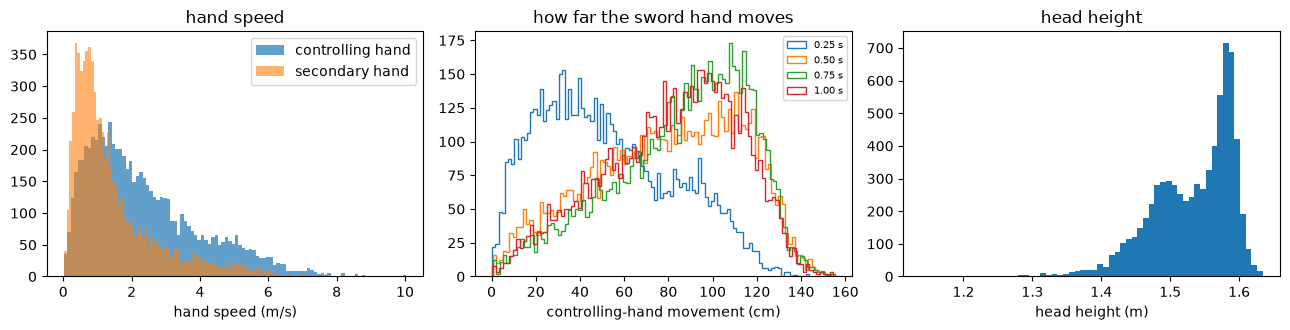

In [5]:
speed = FEATURE_NAMES.index("controlling_hand_speed")
height = FEATURE_NAMES.index("head_height_z")
grip = FEATURE_NAMES.index("grip")
percentiles = np.percentile(last_frame[:, speed], (50, 95, 99, 100))
print("controlling-hand speed: median %.2f m/s, 95th percentile %.2f, 99th %.2f, max %.2f" % tuple(percentiles))
print("head height: %.2f to %.2f m | grip values: %s" % (last_frame[:, height].min(), last_frame[:, height].max(), np.unique(last_frame[:, grip])))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(last_frame[:, speed], bins=100, alpha=0.7, label="controlling hand")
ax[0].hist(last_frame[:, FEATURE_NAMES.index("secondary_hand_speed")], bins=100, alpha=0.6, label="secondary hand")
ax[0].set_xlabel("hand speed (m/s)")
ax[0].legend()
ax[0].set_title("hand speed")
for k, h in enumerate(horizons):
    distance_cm = np.linalg.norm(y[:, 9 * k + 3 : 9 * k + 6], axis=1) * 100  # controlling hand
    ax[1].hist(distance_cm, bins=100, histtype="step", label=f"{h / rate:.2f} s")
ax[1].set_xlabel("controlling-hand movement (cm)")
ax[1].legend(fontsize=7)
ax[1].set_title("how far the sword hand moves")
ax[2].hist(last_frame[:, height], bins=60)
ax[2].set_xlabel("head height (m)")
ax[2].set_title("head height")
fig.tight_layout()
fig.savefig(figures / "features_distributions.png", dpi=130)
plt.show()

## Windows never go outside their segment

In [6]:
for segment, w in zip(segments, all_windows):
    assert w["t0"].min() >= cfg["window_frames"] - 1  # a full window of input before "now"
    assert w["t0"].max() + max(horizons) <= segment.frames - 1  # the furthest target is still inside the segment
print("every window lies fully inside its segment")

every window lies fully inside its segment
